In [1]:
version = 8
#if you change ultron version change it in the model = () aswell

import numpy as np 
import pandas as pd
import kagglehub

path = kagglehub.competition_download('iitb-itc-aiml-team-selection')
print("Path to competition files:", path)


Path to competition files: /kaggle/input/competitions/iitb-itc-aiml-team-selection


In [2]:
train_df = pd.read_csv("/kaggle/input/competitions/iitb-itc-aiml-team-selection/train.csv")
train_df.shape

(28709, 2)

In [3]:
train_df["label"].value_counts()

label
happy       7215
neutral     4965
sad         4830
fear        4097
angry       3995
surprise    3171
disgust      436
Name: count, dtype: int64

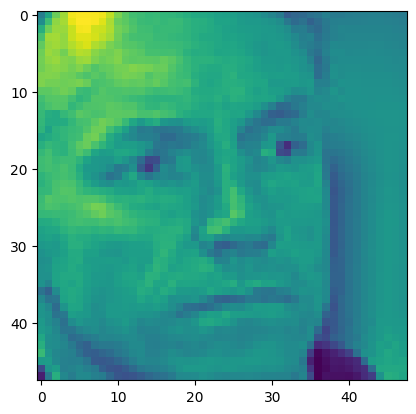

In [4]:
from PIL import Image
import matplotlib.pyplot as plt
im = Image.open("/kaggle/input/competitions/iitb-itc-aiml-team-selection/train/train_00001.jpg")
plt.imshow(im)
plt.show()

In [5]:
print(im.size)
print(im.mode)

(48, 48)
L


In [6]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torchvision import transforms

In [7]:
df_label = pd.read_csv("/kaggle/input/competitions/iitb-itc-aiml-team-selection/train.csv")
unique_labels = sorted(df_label['label'].unique())
label_mapping = {label: idx for idx, label in enumerate(unique_labels)}
inverse_mapping = {idx: label for label, idx in label_mapping.items()}
print(unique_labels)
print("Label Mapping", label_mapping)

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Label Mapping {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


In [8]:
import os
class Customdataset(Dataset):
    def __init__(self, img_dir, pd_dataframe,label_mapping, transform):
        self.img_labels=pd_dataframe
        self.img_dir = img_dir
        self.transform = transform
        self.img_labels['label_int'] = self.img_labels[self.img_labels.columns[1]].map(label_mapping)

    def __len__(self):
        return(len(self.img_labels))

    def __getitem__(self,idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        im = Image.open(img_path)
        label= self.img_labels.loc[idx, "label_int"]
        tensor = self.transform(im)
        return tensor, label

In [9]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees = 7),
    transforms.ColorJitter(brightness=0.18, contrast=0.21),
    transforms.RandomAffine(degrees=0,translate=(0.1, 0.1),scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.2, scale=(0.02,0.1))
])

val_transform = transforms.ToTensor()


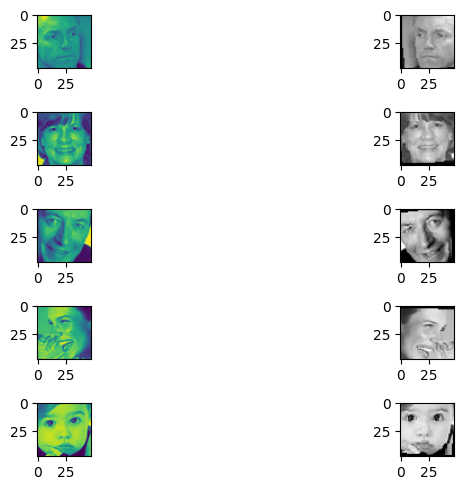

In [10]:
fig, axes = plt.subplots(5,2, figsize=(10,5))

for i in range(1,6):
    im = Image.open(f"/kaggle/input/competitions/iitb-itc-aiml-team-selection/train/train_0000{i}.jpg")
    axes[i-1,0].imshow(im)
    tensor = train_transform(im)
    axes[i-1, 1].imshow(tensor.squeeze().numpy(), cmap="gray")

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold

train_split_2, validation_split = train_test_split(df_label, test_size=0.15,random_state = 37, stratify=df_label["label"])

In [12]:
validation_split = validation_split.reset_index(drop=True)
train_split_2 = train_split_2.reset_index(drop=True)
print(validation_split['label'].value_counts(normalize = True))
print(train_split_2['label'].value_counts(normalize = True))
print(df_label['label'].value_counts(normalize = True))
validation_split.head()

label
happy       0.251219
neutral     0.172974
sad         0.168331
fear        0.142791
angry       0.139076
surprise    0.110518
disgust     0.015092
Name: proportion, dtype: float64
label
happy       0.251332
neutral     0.172937
sad         0.168224
fear        0.142693
angry       0.139169
surprise    0.110442
disgust     0.015204
Name: proportion, dtype: float64
label
happy       0.251315
neutral     0.172942
sad         0.168240
fear        0.142708
angry       0.139155
surprise    0.110453
disgust     0.015187
Name: proportion, dtype: float64


,id,label
0,train_06015.jpg,fear
1,train_03912.jpg,neutral
2,train_17770.jpg,happy
3,train_15176.jpg,surprise
4,train_12315.jpg,angry


In [13]:
train_dataset = Customdataset("/kaggle/input/competitions/iitb-itc-aiml-team-selection/train", train_split_2, label_mapping, train_transform)
val_dataset = Customdataset("/kaggle/input/competitions/iitb-itc-aiml-team-selection/train", validation_split, label_mapping, val_transform)

In [14]:
from torch.utils.data import DataLoader 

train_dataloader = DataLoader(train_dataset, batch_size = 64, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=64, shuffle=False)


In [15]:
class ResidualBlock(nn.Module):
    """Two 3x3 convs with a skip connection. Handles channel/size change via a 1x1 downsample."""
    def __init__(self, in_channels, out_channels, downsample=True):
        super().__init__()
        stride = 2 if downsample else 1

        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                                stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                                stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        # skip path needs to match shape if channels or spatial size changed
        if downsample or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out += identity
        out = self.relu(out)
        return out


class Ultron_level_v6(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        # stem — plain conv, no downsample yet
        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )

        
        self.layer1 = ResidualBlock(32, 64, downsample=True)   
        self.layer2 = ResidualBlock(64, 128, downsample=True)   
        self.layer3 = ResidualBlock(128, 256, downsample=True)
        self.layer4 = ResidualBlock(256, 256, downsample=True)  
        self.layer5 = ResidualBlock(256, 256, downsample=False) 

        self.gap = nn.AdaptiveAvgPool2d(1)   
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)

        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x



# DO NOT FORGET TO CHANGE THIS!!!
model = Ultron_level_v6() # DO NOT FORGET TO CHANGE THIS !!!!

In [16]:
sum(p.numel() for p in model.parameters())

3636455

In [17]:
from sklearn.utils.class_weight import compute_class_weight

class_weights=compute_class_weight(
    class_weight = 'balanced',
    classes = np.array(unique_labels),
    y = train_split_2["label"]
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tensor_weight = torch.tensor(class_weights, dtype=torch.float)
tensor_weight = tensor_weight.to(device)
print(unique_labels)

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [18]:
def writeit(filepath,text):
    with open(filepath,'a', encoding='utf8') as f:
        f.write(text + '\n')

with open(f"/kaggle/working/log{version}.txt", 'w', encoding = 'utf-8') as f:
    pass

logs = f"/kaggle/working/log{version}.txt"

In [19]:
from tqdm.auto import tqdm
import torch.optim 
from sklearn.metrics import f1_score

max_epoch = 47
save_path = "/kaggle/working/model_weightsv3.pth"
lossloss = nn.CrossEntropyLoss(weight=tensor_weight)
hank_pym = torch.optim.AdamW(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(hank_pym, T_max=max_epoch)

model = model.to(device)
model.train()
max_f1score = -1.2
for epoch in range(max_epoch):
    running_loss = 0.0
    pbar = tqdm(train_dataloader, desc = f"Epoch {epoch+1}/{max_epoch}")
    for idx, (images, labels) in enumerate(pbar):
        images = images.to(device)
        labels = labels.to(device)
        hank_pym.zero_grad()
        outputs = model(images)
        loss = lossloss(outputs, labels)
        loss.backward()
        hank_pym.step()
        running_loss +=loss.item()
        pbar.set_postfix(batch_loss=f"{loss.item():.4f}")

    scheduler.step()
    epoch_loss = running_loss/len(train_dataloader)
    print(f"Epoch{epoch+1} completed. average loss : {epoch_loss: .4f}")
    writeit(logs, f"Epoch{epoch+1} completed. average loss : {epoch_loss: .4f}")
    model.eval()
    all_predictions =[]
    all_labels = []
    with torch.no_grad():
        pbar2 = tqdm(val_dataloader,desc = f"validation set Epoch:{epoch+1}/{max_epoch}")
        for idx2, (images, labels) in enumerate(pbar2):
            images=images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            values, predicted = torch.max(outputs, dim=1)
            predicted = predicted.cpu()
            all_predictions.extend(predicted.tolist())
            cpulabels = labels.cpu()
            all_labels.extend(cpulabels.tolist())
        score = f1_score(all_labels, all_predictions, average="macro")
        writeit(logs, f"F1 Score: {score: 4f}")
        print(f"F1 Score: {score: 4f}")
        if max_f1score < score:
            max_f1score = score
            torch.save(model.state_dict(), save_path)
            print(f"New Best F1: {score:4f}, epoch iteration is {epoch+1}, model saved")
            writeit(logs, f"New Best F1: {score:4f}, epoch iteration is {epoch+1}, model saved")


Epoch 1/47:   0%|          | 0/382 [00:00<?, ?it/s]

Epoch1 completed. average loss :  1.9300


validation set Epoch:1/47:   0%|          | 0/68 [00:00<?, ?it/s]

F1 Score:  0.101592
New Best F1: 0.101592, epoch iteration is 1, model saved


Epoch 2/47:   0%|          | 0/382 [00:00<?, ?it/s]

Epoch2 completed. average loss :  1.8629


... (178 outputs left out)

Epoch 47/47:   0%|          | 0/382 [00:00<?, ?it/s]

Epoch47 completed. average loss :  0.7921


validation set Epoch:47/47:   0%|          | 0/68 [00:00<?, ?it/s]

F1 Score:  0.608273


In [20]:
#to take out the labels and everything I need to put this with the XGDboost apporach
model_verification = Ultron_level_v6()
model_verification.load_state_dict(torch.load("/kaggle/input/datasets/happysankhla/cnn-model-weights/model_weightsv5.pth"))
model_verification.eval()
model_verification = model_verification.to(device)
all_probs =[]
all_labels2 = []

all_predictions = []
all_labels = []



In [21]:
with torch.no_grad():
    for batch_idx,(images, labels) in enumerate(val_dataloader):
        images = images.to(device)
        labels = labels.to(device)
        outputs = model_verification(images)

        prob = torch.softmax(outputs, dim=1)
        _, predicted = torch.max(outputs, dim = 1)
        
        prob_np = prob.detach().cpu().numpy()
        labels_np = labels.detach().cpu().numpy()
        all_predictions.extend(predicted.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
        all_probs.append(prob_np)
        all_labels2.append(labels_np)
        if(batch_idx + 1) %50 == 0:
            print(f"processed batch {batch_idx + 1}/len(val_dataloader)")

processed batch 50/len(val_dataloader)


In [22]:
cnn_prob = np.concatenate(all_probs, axis=0)
cnn_true_labels = np.concatenate(all_labels2, axis=0) 
print(f"   Shape: {cnn_prob.shape}")
print(f"   Sample 0 probabilities: {cnn_prob[0]}")
print(f"   Sample 0 true label: {cnn_true_labels[0]}")
np.save("/kaggle/working/cnn_prob.npy", cnn_prob)
np.save("/kaggle/working/cnn_true_labels.npy", cnn_true_labels)


   Shape: (4307, 7)
   Sample 0 probabilities: [2.9208122e-05 5.7808016e-08 8.9853495e-01 2.4228556e-04 1.5181457e-03
 9.6173562e-02 3.5017941e-03]
   Sample 0 true label: 2


In [23]:
import numpy as np
np.savetxt('cnn_prob', cnn_prob, delimiter=",")
np.savetxt('cnn_true_labels', cnn_true_labels, delimiter=",")

In [24]:
from sklearn.metrics import classification_report

print(classification_report(all_labels, all_predictions))
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(all_labels, all_predictions)
print(cm)


              precision    recall  f1-score   support

           0       0.56      0.54      0.55       599
           1       0.55      0.72      0.63        65
           2       0.55      0.42      0.47       615
           3       0.86      0.85      0.86      1082
           4       0.57      0.63      0.60       745
           5       0.48      0.50      0.49       725
           6       0.71      0.78      0.74       476

    accuracy                           0.64      4307
   macro avg       0.61      0.64      0.62      4307
weighted avg       0.64      0.64      0.64      4307

[[325  17  43  25  81  91  17]
 [  8  47   2   1   0   4   3]
 [ 68  10 256  16  63 127  75]
 [ 21   0  17 920  49  41  34]
 [ 57   0  26  56 472 119  15]
 [ 84  10  87  29 142 365   8]
 [ 18   1  38  23  15  11 370]]


In [25]:
class TestDataset(Dataset):
    def __init__ (self, img_dir, dataframe, transform):
        self.img_labels = dataframe
        self.img_dir = img_dir
        self.transform = transform
    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_id = self.img_labels.iloc[idx,0]
        img_path = os.path.join(self.img_dir, img_id)
        im = Image.open(img_path)
        tensor = self.transform(im)
        return tensor, img_id
test_df = pd.read_csv("/kaggle/input/competitions/iitb-itc-aiml-team-selection/test.csv")
test_dataset = TestDataset("/kaggle/input/competitions/iitb-itc-aiml-team-selection/test", test_df, val_transform)
test_dataloader = DataLoader(test_dataset, batch_size = 64, shuffle = False)
print(len(test_dataloader))
print(len(test_dataloader.dataset))

113
7178


In [26]:
all_test_preds = []
all_test_ids = []

with torch.no_grad():
    for images, ids in test_dataloader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, dim=1)
        all_test_preds.extend(predicted.cpu().tolist())
        all_test_ids.extend(list(ids))

In [27]:
predicted_labels = [inverse_mapping[p] for p in all_test_preds]

submission_df = pd.DataFrame({
    "id" : all_test_ids,
    "label" : predicted_labels
})

submission_df.to_csv(f"submission_v{version}.csv", index = False)
print(submission_df.shape)
submission_df.head()

(7178, 2)


,id,label
0,test_00001.jpg,sad
1,test_00002.jpg,happy
2,test_00003.jpg,neutral
3,test_00004.jpg,neutral
4,test_00005.jpg,surprise


In [28]:
train_df = pd.read_csv("/kaggle/input/competitions/iitb-itc-aiml-team-selection/train.csv")
train_dataset = TestDataset("/kaggle/input/competitions/iitb-itc-aiml-team-selection/train", train_df, val_transform)
train_dataloader = DataLoader(train_dataset, batch_size = 64, shuffle = False)

In [29]:
all_test_preds1 = []
all_test_ids1 = []

with torch.no_grad():
    for images, ids in train_dataloader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, dim=1)
        all_test_preds1.extend(predicted.cpu().tolist())
        all_test_ids1.extend(list(ids))

In [30]:
predicted_labels1 = [inverse_mapping[p] for p in all_test_preds1]

submission_df = pd.DataFrame({
    "id" : all_test_ids1,
    "label" : predicted_labels1
})

submission_df.to_csv(f"verification_v{version}.csv", index = False)
print(submission_df.shape)
submission_df.head()

(28709, 2)


,id,label
0,train_00001.jpg,fear
1,train_00002.jpg,happy
2,train_00003.jpg,happy
3,train_00004.jpg,happy
4,train_00005.jpg,neutral


In [31]:
check = pd.read_csv('/kaggle/input/competitions/iitb-itc-aiml-team-selection/train.csv')

print(check.shape)
check.head()

(28709, 2)


,id,label
0,train_00001.jpg,fear
1,train_00002.jpg,happy
2,train_00003.jpg,happy
3,train_00004.jpg,happy
4,train_00005.jpg,neutral


In [32]:
merged = check.merge(submission_df, on='id', suffixes=('_pred', '_true'))

y_true = merged['label_true']
y_pred = merged['label_pred']

print(classification_report(y_true, y_pred, digits =3))
print(confusion_matrix(y_true, y_pred))
print("Macro F1:", f1_score(y_true, y_pred, average="macro"))

              precision    recall  f1-score   support

       angry      0.652     0.644     0.648      4044
     disgust      0.933     0.665     0.777       612
        fear      0.512     0.637     0.568      3293
       happy      0.874     0.901     0.887      7001
     neutral      0.740     0.616     0.673      5966
         sad      0.548     0.652     0.596      4064
    surprise      0.892     0.758     0.820      3729

    accuracy                          0.716     28709
   macro avg      0.736     0.696     0.710     28709
weighted avg      0.731     0.716     0.720     28709

[[2606   15  442  163  291  475   52]
 [ 109  407   32   11   13   36    4]
 [ 265    1 2097   90  177  550  113]
 [ 110    0  101 6305  269  128   88]
 [ 494    2  436  354 3676  941   63]
 [ 320    7  490  111  464 2649   23]
 [  91    4  499  181   75   51 2828]]
Macro F1: 0.7096549249284949
